In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
os.makedirs(BK, exist_ok=True)

items = {
    "data_raw":      "/content/data_raw",        # NSTP photos + "other" images
    "nstp_labeled":  "/content/nstp_labeled",    # Roboflow export
    "nstp_det":      "/content/nstp_det",        # merged train/val dataset
    "best_weights":  "/content/runs/nstp_det/weights",   # best.pt / last.pt
}
for name, path in items.items():
    if os.path.isdir(path) and os.listdir(path):
        shutil.make_archive(f"/content/{name}", "zip", path)
        shutil.copy(f"/content/{name}.zip", f"{BK}/{name}.zip")
        print("saved", name, round(os.path.getsize(f"{BK}/{name}.zip") / 1e6, 1), "MB")
    else:
        print("skipped (not found or empty):", name)

Mounted at /content/drive
skipped (not found or empty): data_raw
skipped (not found or empty): nstp_labeled
skipped (not found or empty): nstp_det
skipped (not found or empty): best_weights


### Restore (run at the start of a new session)

In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
targets = {
    "data_raw":     "/content/data_raw",
    "nstp_labeled": "/content/nstp_labeled",
    "nstp_det":     "/content/nstp_det",
    "best_weights": "/content/runs/nstp_det/weights",
}
for name, path in targets.items():
    z = f"{BK}/{name}.zip"
    if os.path.exists(z):
        os.makedirs(path, exist_ok=True)
        shutil.unpack_archive(z, path)
        print("restored", name)
    else:
        print("no backup for", name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
restored data_raw
restored nstp_labeled
restored nstp_det
restored best_weights


In [ ]:
import os, glob
for p in ["/content/data_raw/NSTP", "/content/data_raw/other", "/content/data_raw/hard_neg",
          "/content/nstp_det/images/train", "/content/nstp_det/images/val"]:
    print(p, len(glob.glob(p + "/*")) if os.path.isdir(p) else "MISSING")

/content/data_raw/NSTP 36
/content/data_raw/other 342
/content/data_raw/hard_neg 85
/content/nstp_det/images/train 326
/content/nstp_det/images/val 86


## Classifier code:

### Cell 1: check the NSTP photos and fetch "other" images (run this for detector route too)

In [ ]:
import os, glob, requests, io, time
from PIL import Image

print("NSTP photos:", len(glob.glob("/content/data_raw/NSTP/*")))

HEADERS = {"User-Agent": "building-classifier-test/0.1 (student project)"}
API = "https://commons.wikimedia.org/w/api.php"
OTHER = "/content/data_raw/other"
os.makedirs(OTHER, exist_ok=True)

queries = ["Islamabad building", "Islamabad street", "Pakistan university campus", "office building",
           "modern glass building", "apartment building", "shopping mall building", "Lahore building",
           "Karachi building", "road with trees", "parking lot", "city park trees"]
n = len(os.listdir(OTHER))
for q in queries:
    params = {"action": "query", "format": "json", "generator": "search",
              "gsrsearch": f"{q} filetype:bitmap", "gsrnamespace": 6, "gsrlimit": 30,
              "prop": "imageinfo", "iiprop": "url|mime", "iiurlwidth": 800}
    r = requests.get(API, params=params, headers=HEADERS, timeout=30).json()
    for p in r.get("query", {}).get("pages", {}).values():
        info = p.get("imageinfo", [{}])[0]
        url = info.get("thumburl") or info.get("url")
        if not url or info.get("mime") != "image/jpeg":
            continue
        try:
            img = Image.open(io.BytesIO(requests.get(url, headers=HEADERS, timeout=30).content)).convert("RGB")
            img.save(f"{OTHER}/c_{n:04d}.jpg", quality=90); n += 1
        except Exception:
            continue
        time.sleep(0.3)
print("other images:", len(os.listdir(OTHER)))

NSTP photos: 36
other images: 342


In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
os.makedirs(BK, exist_ok=True)

items = {
    "data_raw":      "/content/data_raw",        # NSTP photos + "other" images
    "nstp_labeled":  "/content/nstp_labeled",    # Roboflow export
    "nstp_det":      "/content/nstp_det",        # merged train/val dataset
    "best_weights":  "/content/runs/nstp_det/weights",   # best.pt / last.pt
}
for name, path in items.items():
    if os.path.isdir(path) and os.listdir(path):
        shutil.make_archive(f"/content/{name}", "zip", path)
        shutil.copy(f"/content/{name}.zip", f"{BK}/{name}.zip")
        print("saved", name, round(os.path.getsize(f"{BK}/{name}.zip") / 1e6, 1), "MB")
    else:
        print("skipped (not found or empty):", name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saved data_raw 85.9 MB
saved nstp_labeled 3.2 MB
saved nstp_det 91.0 MB
saved best_weights 9.6 MB


### Cell 2: build the dataset

In [ ]:
import os, glob, random, shutil
import numpy as np
from PIL import Image
random.seed(0)

def dhash(p, size=8):
    im = Image.open(p).convert("L").resize((size + 1, size))
    a = np.asarray(im, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

def dedupe(paths, thr=6):
    kept, hashes = [], []
    for p in paths:
        try: h = dhash(p)
        except Exception: continue
        if all((h != k).sum() > thr for k in hashes):
            kept.append(p); hashes.append(h)
    return kept

nstp = dedupe(sorted(glob.glob("/content/data_raw/NSTP/*")))
other = dedupe(sorted(glob.glob("/content/data_raw/other/*")))
print("NSTP after dedupe:", len(nstp), "| other:", len(other))

OUT = "/content/cls_data"
shutil.rmtree(OUT, ignore_errors=True)

def save(paths, split, cls, copies=1):
    os.makedirs(f"{OUT}/{split}/{cls}", exist_ok=True)
    for i, p in enumerate(paths):
        try: im = Image.open(p).convert("RGB")
        except Exception: continue
        for c in range(copies):
            im.save(f"{OUT}/{split}/{cls}/{i:04d}_{c}.jpg", quality=92)

random.shuffle(nstp); random.shuffle(other)
n_val = max(5, int(0.2 * len(nstp)))
save(nstp[n_val:], "train", "NSTP", copies=5)
save(nstp[:n_val], "val", "NSTP")
k = int(0.8 * len(other))
save(other[:k], "train", "other"); save(other[k:], "val", "other")
print("NSTP train/val:", len(nstp) - n_val, "/", n_val, "| other train/val:", k, "/", len(other) - k)

### Cell 3: train and measure

In [ ]:
OUT = "/content/cls_data"
from ultralytics import YOLO
try:
    model = YOLO("yolo26n-cls.pt")
except Exception:
    model = YOLO("yolo11n-cls.pt")
model.train(data=OUT, imgsz=224, epochs=40, batch=32, patience=15, fliplr=0.0, scale=0.5,
            erasing=0.3, auto_augment="randaugment", hsv_h=0.02, hsv_s=0.7, hsv_v=0.4,
            project="/content/runs", name="nstp_cls")

import glob, numpy as np
best = YOLO("/content/runs/nstp_cls/weights/best.pt")
nid = [k for k, v in best.names.items() if v == "NSTP"][0]
def probs(folder):
    ps = glob.glob(f"{folder}/*.jpg")
    return [round(float(r.probs.data[nid]), 2) for r in best.predict(ps, imgsz=224, verbose=False)]
a, b = probs(f"{OUT}/val/NSTP"), probs(f"{OUT}/val/other")
print("NSTP val  :", sorted(a))
print("other val : max", max(b), "| median", np.median(b))

## Detector Code

### Backup to drive (run it after each stage)
Run it right after you upload the photos, again after Cell B builds the dataset, and again after training finishes. It skips any folder that doesn't exist yet, so it's safe at any point

In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
os.makedirs(BK, exist_ok=True)

items = {
    "data_raw":      "/content/data_raw",        # NSTP photos + "other" images
    "nstp_labeled":  "/content/nstp_labeled",    # Roboflow export
    "nstp_det":      "/content/nstp_det",        # merged train/val dataset
    "best_weights":  "/content/runs/nstp_det/weights",   # best.pt / last.pt
}
for name, path in items.items():
    if os.path.isdir(path) and os.listdir(path):
        shutil.make_archive(f"/content/{name}", "zip", path)
        shutil.copy(f"/content/{name}.zip", f"{BK}/{name}.zip")
        print("saved", name, round(os.path.getsize(f"{BK}/{name}.zip") / 1e6, 1), "MB")
    else:
        print("skipped (not found or empty):", name)

### Restore (run at the start of a new session)

In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
targets = {
    "data_raw":     "/content/data_raw",
    "nstp_labeled": "/content/nstp_labeled",
    "nstp_det":     "/content/nstp_det",
    "best_weights": "/content/runs/nstp_det/weights",
}
for name, path in targets.items():
    z = f"{BK}/{name}.zip"
    if os.path.exists(z):
        os.makedirs(path, exist_ok=True)
        shutil.unpack_archive(z, path)
        print("restored", name)
    else:
        print("no backup for", name)

### Resume training after a disconnect

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/runs/nstp_det/weights/last.pt")
model.train(resume=True)

### Cell A: upload the Roboflow zip

In [ ]:
import os, glob, zipfile
from google.colab import files
up = files.upload()                     # select the Roboflow zip
os.makedirs("/content/nstp_labeled", exist_ok=True)
zipfile.ZipFile(list(up.keys())[0]).extractall("/content/nstp_labeled")
print(len(glob.glob("/content/nstp_labeled/**/images/*", recursive=True)), "images,",
      len(glob.glob("/content/nstp_labeled/**/labels/*.txt", recursive=True)), "label files")

Saving Object Detection.v1i.yolov8.zip to Object Detection.v1i.yolov8.zip
35 images, 35 label files


### Cell B: merge, deduplicate and split

In [ ]:
import glob, os, random, shutil
import numpy as np
from PIL import Image
random.seed(0)

SRC, OUT = "/content/nstp_labeled", "/content/nstp_det"

def dhash(p, size=8):
    a = np.asarray(Image.open(p).convert("L").resize((size + 1, size)), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

def dedupe(paths, thr=6):
    kept, hs = [], []
    for p in paths:
        try: h = dhash(p)
        except Exception: continue
        if all((h != k).sum() > thr for k in hs):
            kept.append(p); hs.append(h)
    return kept

def label_path(p):
    return p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

imgs = sorted(p for e in ("jpg", "jpeg", "png") for p in glob.glob(f"{SRC}/**/images/*.{e}", recursive=True))
imgs = [p for p in imgs if os.path.exists(label_path(p)) and os.path.getsize(label_path(p)) > 0]
pos = dedupe(imgs)
others = dedupe(sorted(glob.glob("/content/data_raw/other/*.jpg")))
print("NSTP labeled:", len(imgs), "-> after dedupe:", len(pos), "| other:", len(others))

shutil.rmtree(OUT, ignore_errors=True)
for s in ("train", "val"):
    os.makedirs(f"{OUT}/images/{s}", exist_ok=True); os.makedirs(f"{OUT}/labels/{s}", exist_ok=True)

def write(p, split, name, boxes=None):
    Image.open(p).convert("RGB").save(f"{OUT}/images/{split}/{name}.jpg", quality=92)
    open(f"{OUT}/labels/{split}/{name}.txt", "w").write(boxes or "")

def boxes_of(p):                         # force every class id to 0 (NSTP)
    rows = [l.split() for l in open(label_path(p)).read().splitlines() if l.strip()]
    return "\n".join("0 " + " ".join(r[1:5]) for r in rows)

random.shuffle(pos); random.shuffle(others)
n_val = max(4, int(0.2 * len(pos)))
for i, p in enumerate(pos[:n_val]):
    write(p, "val", f"pos_{i}", boxes_of(p))
for i, p in enumerate(pos[n_val:]):
    for c in range(4):                    # repeat training positives, augmentation varies each copy
        write(p, "train", f"pos_{i}_{c}", boxes_of(p))
for i, p in enumerate(others[:80]):
    write(p, "val", f"neg_{i}")
for i, p in enumerate(others[80:380]):
    write(p, "train", f"neg_{i}")

import yaml
yaml.dump({"path": OUT, "train": "images/train", "val": "images/val", "names": {0: "NSTP"}},
          open(f"{OUT}/data.yaml", "w"))
print("val positives:", n_val, "| train positives:", len(pos) - n_val, "(x4 copies) | train negatives:", len(others[80:380]))

NSTP labeled: 35 -> after dedupe: 32 | other: 302
val positives: 6 | train positives: 26 (x4 copies) | train negatives: 222


### New cell B (updated)

NSTP labeled: 35 -> after dedupe: 32 | other: 302
val positives: 6 | train positives: 26 (x4 copies)
example label line: 0 0.499004 0.495090 0.998008 0.649755


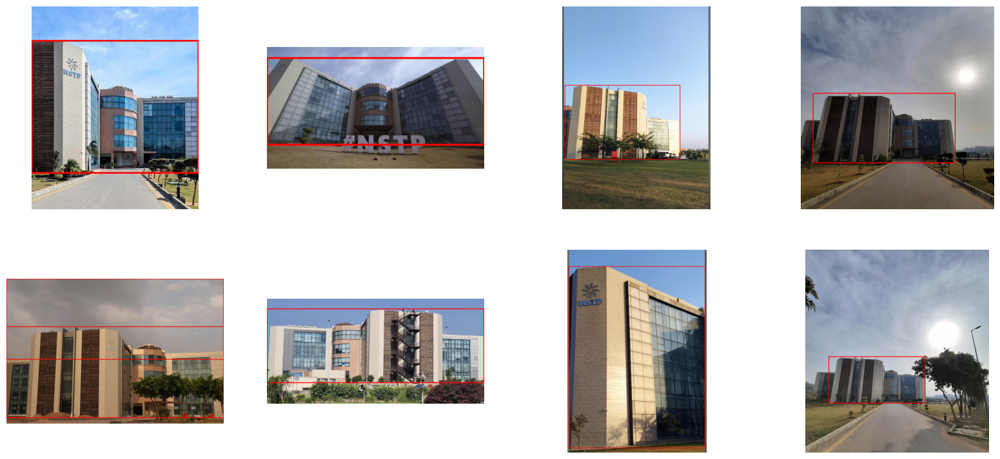

In [ ]:
import glob, os, random, shutil, yaml
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
random.seed(0)

SRC, OUT = "/content/nstp_labeled", "/content/nstp_det"

def dhash(p, size=8):
    a = np.asarray(Image.open(p).convert("L").resize((size + 1, size)), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

def dedupe(paths, thr=6):
    kept, hs = [], []
    for p in paths:
        try: h = dhash(p)
        except Exception: continue
        if all((h != k).sum() > thr for k in hs):
            kept.append(p); hs.append(h)
    return kept

def label_path(p):
    return p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"

def boxes_of(p):
    out = []
    for line in open(label_path(p)).read().splitlines():
        t = line.split()
        if len(t) < 5:
            continue
        v = list(map(float, t[1:]))
        if len(v) == 4:                              # already a box: cx cy w h
            cx, cy, w, h = v
        elif len(v) % 2 == 0:                        # polygon: x1 y1 x2 y2 ... -> enclosing box
            xs, ys = v[0::2], v[1::2]
            x0, x1, y0, y1 = min(xs), max(xs), min(ys), max(ys)
            cx, cy, w, h = (x0 + x1) / 2, (y0 + y1) / 2, x1 - x0, y1 - y0
        else:
            cx, cy, w, h = v[:4]
        out.append(f"0 {cx:.6f} {cy:.6f} {w:.6f} {h:.6f}")
    return "\n".join(out)

imgs = sorted(p for e in ("jpg", "jpeg", "png") for p in glob.glob(f"{SRC}/**/images/*.{e}", recursive=True))
imgs = [p for p in imgs if os.path.exists(label_path(p)) and os.path.getsize(label_path(p)) > 0]
pos = dedupe(imgs)
others = dedupe(sorted(glob.glob("/content/data_raw/other/*.jpg")))
print("NSTP labeled:", len(imgs), "-> after dedupe:", len(pos), "| other:", len(others))

shutil.rmtree(OUT, ignore_errors=True)
for s in ("train", "val"):
    os.makedirs(f"{OUT}/images/{s}", exist_ok=True); os.makedirs(f"{OUT}/labels/{s}", exist_ok=True)

def write(p, split, name, boxes=None):
    Image.open(p).convert("RGB").save(f"{OUT}/images/{split}/{name}.jpg", quality=92)
    open(f"{OUT}/labels/{split}/{name}.txt", "w").write(boxes or "")

random.shuffle(pos); random.shuffle(others)
n_val = max(4, int(0.2 * len(pos)))
for i, p in enumerate(pos[:n_val]):
    write(p, "val", f"pos_{i}", boxes_of(p))
for i, p in enumerate(pos[n_val:]):
    for c in range(4):
        write(p, "train", f"pos_{i}_{c}", boxes_of(p))
for i, p in enumerate(others[:80]):
    write(p, "val", f"neg_{i}")
for i, p in enumerate(others[80:380]):
    write(p, "train", f"neg_{i}")

yaml.dump({"path": OUT, "train": "images/train", "val": "images/val", "names": {0: "NSTP"}},
          open(f"{OUT}/data.yaml", "w"))
print("val positives:", n_val, "| train positives:", len(pos) - n_val, "(x4 copies)")

# --- check: draw 8 training boxes ---
pos_l = sorted(l for l in glob.glob(f"{OUT}/labels/train/pos_*.txt") if os.path.getsize(l) > 0)
pick = pos_l[::max(1, len(pos_l) // 8)][:8]
print("example label line:", open(pick[0]).read().splitlines()[0])
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, l in zip(axes.flat, pick):
    img = cv2.cvtColor(cv2.imread(l.replace("/labels/", "/images/").replace(".txt", ".jpg")), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    for line in open(l):
        cx, cy, w, h = map(float, line.split()[1:5])
        cv2.rectangle(img, (int((cx - w/2) * W), int((cy - h/2) * H)),
                      (int((cx + w/2) * W), int((cy + h/2) * H)), (255, 0, 0), 4)
    ax.imshow(img); ax.axis("off")
plt.show()

In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
os.makedirs(BK, exist_ok=True)

items = {
    "data_raw":      "/content/data_raw",        # NSTP photos + "other" images
    "nstp_labeled":  "/content/nstp_labeled",    # Roboflow export
    "nstp_det":      "/content/nstp_det",        # merged train/val dataset
    "best_weights":  "/content/runs/nstp_det/weights",   # best.pt / last.pt
}
for name, path in items.items():
    if os.path.isdir(path) and os.listdir(path):
        shutil.make_archive(f"/content/{name}", "zip", path)
        shutil.copy(f"/content/{name}.zip", f"{BK}/{name}.zip")
        print("saved", name, round(os.path.getsize(f"{BK}/{name}.zip") / 1e6, 1), "MB")
    else:
        print("skipped (not found or empty):", name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saved data_raw 85.9 MB
saved nstp_labeled 3.2 MB
saved nstp_det 91.0 MB
saved best_weights 9.6 MB


### Cell C: train and check

In [ ]:
!pip install -q ultralytics==8.4.104
import glob, os
from ultralytics import YOLO
OUT = "/content/nstp_det"

model = YOLO("yolo26n.pt")
model.train(data=f"{OUT}/data.yaml", imgsz=320, epochs=80, patience=0, batch=16,
            optimizer="AdamW", lr0=0.001, lrf=0.1, cos_lr=True, warmup_epochs=3,
            close_mosaic=15, fliplr=0.0, scale=0.4, degrees=0,
            hsv_h=0.02, hsv_s=0.6, hsv_v=0.4,
            project="/content/runs", name="nstp_det2")

best = YOLO("/content/runs/nstp_det2/weights/best.pt")
val_imgs = sorted(glob.glob(f"{OUT}/images/val/*"))
is_pos = [os.path.getsize(p.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt") > 0 for p in val_imgs]
confs = [round(float(r.boxes.conf.max()), 2) if len(r.boxes) else 0.0
         for r in best.predict(val_imgs, imgsz=(224, 320), conf=0.05, verbose=False, stream=True)]
pos_c = sorted(c for c, f in zip(confs, is_pos) if f)
neg_c = sorted(c for c, f in zip(confs, is_pos) if not f)
print("NSTP val, top confidence per image:", pos_c)
print("other val: highest", max(neg_c), "| 90th percentile", neg_c[int(0.9 * len(neg_c))])

New https://pypi.org/project/ultralytics/8.4.174 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.104 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=15, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/nstp_det/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.02, hsv_s=0.6, hsv_v=0.4, imgsz=320, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentu

In [ ]:
from google.colab import drive
import os, shutil

drive.mount("/content/drive")
BK = "/content/drive/MyDrive/nstp_project"
os.makedirs(BK, exist_ok=True)

items = {
    "data_raw":      "/content/data_raw",        # NSTP photos + "other" images
    "nstp_labeled":  "/content/nstp_labeled",    # Roboflow export
    "nstp_det":      "/content/nstp_det",        # merged train/val dataset
    "best_weights":  "/content/runs/nstp_det/weights",   # best.pt / last.pt
}
for name, path in items.items():
    if os.path.isdir(path) and os.listdir(path):
        shutil.make_archive(f"/content/{name}", "zip", path)
        shutil.copy(f"/content/{name}.zip", f"{BK}/{name}.zip")
        print("saved", name, round(os.path.getsize(f"{BK}/{name}.zip") / 1e6, 1), "MB")
    else:
        print("skipped (not found or empty):", name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
saved data_raw 85.9 MB
saved nstp_labeled 3.2 MB
saved nstp_det 91.0 MB
saved best_weights 9.6 MB


### Resume training after a disconnect

In [ ]:
from ultralytics import YOLO
model = YOLO("/content/runs/nstp_det/weights/last.pt")
model.train(resume=True)

Export and build the files for Maixcam

In [ ]:
from ultralytics import YOLO
import glob, os, shutil, zipfile
from google.colab import files

OUT = "/content/nstp_det"
best = YOLO("/content/runs/nstp_det2/weights/best.pt")
onnx_path = best.export(format="onnx", imgsz=(224, 320), opset=17, simplify=True)

pos = sorted(glob.glob(f"{OUT}/images/train/pos_*_0.jpg"))
neg = sorted(glob.glob(f"{OUT}/images/train/neg_*.jpg"))[:74]
os.makedirs("/content/calib_nstp", exist_ok=True)
for i, p in enumerate(pos + neg):
    shutil.copy(p, f"/content/calib_nstp/img_{i:03d}.jpg")
with zipfile.ZipFile("/content/calib_nstp.zip", "w") as z:
    for f in sorted(os.listdir("/content/calib_nstp")):
        z.write(f"/content/calib_nstp/{f}", arcname=f)
print("calibration images:", len(pos) + len(neg))

mud = """[basic]
type = cvimodel
model = nstp.cvimodel

[extra]
model_type = yolo26
input_type = rgb
mean = 0, 0, 0
scale = 0.00392156862745098, 0.00392156862745098, 0.00392156862745098
labels = NSTP
"""
open("/content/nstp.mud", "w").write(mud)

for p in [onnx_path, "/content/calib_nstp.zip", "/content/nstp.mud"]:
    files.download(p)

Ultralytics 8.4.104 🚀 Python-3.13.15 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
YOLO26n summary (fused): 122 layers, 2,375,031 parameters, 0 gradients, 5.2 GFLOPs

PyTorch: starting from '/content/runs/nstp_det2/weights/best.pt' with input shape (1, 3, 224, 320) BCHW and output shape(s) (1, 300, 6) (5.1 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.97...
ONNX: export success ✅ 2.1s, saved as '/content/runs/nstp_det2/weights/best.onnx' (9.2 MB)

Export complete (2.5s)
Results saved to /content/runs/nstp_det2/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/nstp_det2/weights/best.onnx imgsz=224,320 
Validate:        yolo val task=detect model=/content/runs/nstp_det2/weights/best.onnx imgsz=224,320 data=/content/nstp_det/data.yaml  WARNING ⚠️ non-PyTorch val requires square images, 'imgsz=[224, 320]' will not work. Use export 'imgsz=320' if val is required.
Visualize:       https://netron.app
calibration imag

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Testing SIFT and ORB

In [ ]:
import glob, os, random, cv2, numpy as np
from sklearn.metrics import roc_auc_score
random.seed(0)
OUT = "/content/nstp_det"

def load(p, max_side=800):
    im = cv2.imread(p); s = max_side / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s) if s < 1 else im

def crop_nstp(img, label_file, margin=0.03):
    rows = [list(map(float, l.split()[1:5])) for l in open(label_file).read().splitlines() if l.strip()]
    x0 = min(r[0] - r[2] / 2 for r in rows); x1 = max(r[0] + r[2] / 2 for r in rows)
    y0 = min(r[1] - r[3] / 2 for r in rows); y1 = max(r[1] + r[3] / 2 for r in rows)
    H, W = img.shape[:2]
    return img[max(0, int((y0 - margin) * H)):min(H, int((y1 + margin) * H)),
               max(0, int((x0 - margin) * W)):min(W, int((x1 + margin) * W))]

pos_imgs = sorted(glob.glob(f"{OUT}/images/val/pos_*.jpg")) + sorted(glob.glob(f"{OUT}/images/train/pos_*_0.jpg"))
neg_imgs = sorted(glob.glob(f"{OUT}/images/val/neg_*.jpg")) + sorted(glob.glob(f"{OUT}/images/train/neg_*.jpg"))[:40]
lbl = lambda p: p.replace("/images/", "/labels/").replace(".jpg", ".txt")
print("NSTP images:", len(pos_imgs), "| negatives:", len(neg_imgs))

clahe = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8))
gray = lambda im: clahe.apply(cv2.cvtColor(im, cv2.COLOR_BGR2GRAY))
EXTRACT = {"SIFT": cv2.SIFT_create(contrastThreshold=0.02), "ORB": cv2.ORB_create(nfeatures=2000)}
NORM = {"SIFT": cv2.NORM_L2, "ORB": cv2.NORM_HAMMING}

def feats(im, m):
    kp, des = EXTRACT[m].detectAndCompute(gray(im), None)
    return np.float32([k.pt for k in kp]), des

def inliers(f1, f2, m, ratio=0.8):
    (p1, d1), (p2, d2) = f1, f2
    if d1 is None or d2 is None or len(p1) < 8 or len(p2) < 8: return 0
    good = [a for a, b in cv2.BFMatcher(NORM[m]).knnMatch(d1, d2, k=2) if a.distance < ratio * b.distance] \
           if len(d2) > 1 else []
    if len(good) < 8: return 0
    src = np.float32([p1[g.queryIdx] for g in good]).reshape(-1, 1, 2)
    dst = np.float32([p2[g.trainIdx] for g in good]).reshape(-1, 1, 2)
    H, mask = cv2.findHomography(src, dst, cv2.USAC_MAGSAC, 8.0)
    return int(mask.sum()) if mask is not None else 0

imgs = {p: load(p) for p in pos_imgs + neg_imgs}
crops = {p: crop_nstp(imgs[p], lbl(p)) for p in pos_imgs}
test_f = {m: {p: feats(imgs[p], m) for p in imgs} for m in EXTRACT}

for m in EXTRACT:
    for k in (1, 2, 3):
        aucs, recalls = [], []
        for trial in range(6):
            refs = random.sample(pos_imgs, k)
            ref_f = [feats(crops[r], m) for r in refs]
            tests = [p for p in imgs if p not in refs]
            labels = [p in pos_imgs for p in tests]
            scores = [max(inliers(rf, test_f[m][p], m) for rf in ref_f) for p in tests]
            aucs.append(roc_auc_score(labels, scores))
            neg_max = max(s for s, l in zip(scores, labels) if not l)
            pos_s = [s for s, l in zip(scores, labels) if l]
            recalls.append(np.mean([s > neg_max for s in pos_s]))
        print(f"{m} | {k} reference image(s): AUC {np.mean(aucs):.2f} (min {np.min(aucs):.2f}) | "
              f"NSTP found with zero false alarms: {np.mean(recalls):.0%}")

NSTP images: 32 | negatives: 120
SIFT | 1 reference image(s): AUC 0.56 (min 0.42) | NSTP found with zero false alarms: 11%
SIFT | 2 reference image(s): AUC 0.51 (min 0.45) | NSTP found with zero false alarms: 4%
SIFT | 3 reference image(s): AUC 0.55 (min 0.48) | NSTP found with zero false alarms: 13%
ORB | 1 reference image(s): AUC 0.66 (min 0.61) | NSTP found with zero false alarms: 13%
ORB | 2 reference image(s): AUC 0.67 (min 0.60) | NSTP found with zero false alarms: 13%
ORB | 3 reference image(s): AUC 0.69 (min 0.61) | NSTP found with zero false alarms: 15%


In [ ]:
import cv2, numpy as np, glob
OUT = "/content/nstp_det"
p = sorted(glob.glob(f"{OUT}/images/val/pos_*.jpg"))[0]
img = cv2.imread(p); s = 600 / max(img.shape[:2]); img = cv2.resize(img, None, fx=s, fy=s)
h, w = img.shape[:2]
M = cv2.getRotationMatrix2D((w / 2, h / 2), 15, 0.8)
warped = cv2.warpAffine(img, M, (w, h))
sift = cv2.SIFT_create(contrastThreshold=0.02)
k1, d1 = sift.detectAndCompute(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), None)
k2, d2 = sift.detectAndCompute(cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY), None)
good = [a for a, b in cv2.BFMatcher().knnMatch(d1, d2, k=2) if a.distance < 0.8 * b.distance]
src = np.float32([k1[g.queryIdx].pt for g in good]).reshape(-1, 1, 2)
dst = np.float32([k2[g.trainIdx].pt for g in good]).reshape(-1, 1, 2)
H, mask = cv2.findHomography(src, dst, cv2.USAC_MAGSAC, 5.0)
print("keypoints:", len(k1), len(k2), "| good matches:", len(good), "| inliers:", int(mask.sum()))

keypoints: 2042 1612 | good matches: 911 | inliers: 856


### Testing SuperPoint + LightGlue

In [ ]:
!pip install -q git+https://github.com/cvg/LightGlue.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 60.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 124.5 MB/s eta 0:00:00


### Clear the folders, so the second upload doesn’t duplicate files

In [ ]:
import shutil, os
for n in ("ref", "pos", "neg"):
    shutil.rmtree(f"/content/real/{n}", ignore_errors=True); os.makedirs(f"/content/real/{n}")

In [ ]:
import torch, glob, random, time, cv2, numpy as np
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd
from sklearn.metrics import roc_auc_score
random.seed(0)
OUT = "/content/nstp_det"
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)
t0 = time.time()

extractor = SuperPoint(max_num_keypoints=1024).eval().to(dev)
matcher = LightGlue(features="superpoint").eval().to(dev)

def load(p, max_side=600):
    im = cv2.imread(p); s = max_side / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s) if s < 1 else im

def crop_nstp(img, label_file, margin=0.03):
    rows = [list(map(float, l.split()[1:5])) for l in open(label_file).read().splitlines() if l.strip()]
    x0 = min(r[0] - r[2] / 2 for r in rows); x1 = max(r[0] + r[2] / 2 for r in rows)
    y0 = min(r[1] - r[3] / 2 for r in rows); y1 = max(r[1] + r[3] / 2 for r in rows)
    H, W = img.shape[:2]
    return img[max(0, int((y0 - margin) * H)):min(H, int((y1 + margin) * H)),
               max(0, int((x0 - margin) * W)):min(W, int((x1 + margin) * W))]

pos_imgs = sorted(glob.glob(f"{OUT}/images/val/pos_*.jpg")) + sorted(glob.glob(f"{OUT}/images/train/pos_*_0.jpg"))
neg_imgs = sorted(glob.glob(f"{OUT}/images/val/neg_*.jpg"))[:40] + sorted(glob.glob(f"{OUT}/images/train/neg_*.jpg"))[:20]
lbl = lambda p: p.replace("/images/", "/labels/").replace(".jpg", ".txt")
print("NSTP images:", len(pos_imgs), "| negatives:", len(neg_imgs))

def feats(im):
    t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(dev)
    with torch.no_grad():
        return extractor.extract(t)

def inliers(f0, f1):
    with torch.no_grad():
        out = matcher({"image0": f0, "image1": f1})
    f0, f1, out = [rbd(x) for x in (f0, f1, out)]
    m = out["matches"]
    if len(m) < 8: return 0
    p0 = f0["keypoints"][m[:, 0]].cpu().numpy().reshape(-1, 1, 2)
    p1 = f1["keypoints"][m[:, 1]].cpu().numpy().reshape(-1, 1, 2)
    H, mask = cv2.findHomography(p0, p1, cv2.USAC_MAGSAC, 8.0)
    return int(mask.sum()) if mask is not None else 0

imgs = {p: load(p) for p in pos_imgs + neg_imgs}
cand = random.sample(pos_imgs, min(12, len(pos_imgs)))
crops = {p: crop_nstp(imgs[p], lbl(p)) for p in cand}
test_f = {p: feats(imgs[p]) for p in imgs}

S = {}
for i, r in enumerate(cand):
    rf = feats(crops[r])
    for p in imgs:
        if p != r:
            S[(r, p)] = inliers(rf, test_f[p])
    print(f"reference {i + 1}/{len(cand)} done ({time.time() - t0:.0f}s)", flush=True)

for k in (1, 2, 3):
    aucs, recalls = [], []
    for trial in range(30):
        refs = random.sample(cand, k)
        tests = [p for p in imgs if p not in refs]
        labels = [p in pos_imgs for p in tests]
        scores = [max(S[(r, p)] for r in refs) for p in tests]
        aucs.append(roc_auc_score(labels, scores))
        neg_max = max(s for s, l in zip(scores, labels) if not l)
        recalls.append(np.mean([s > neg_max for s, l in zip(scores, labels) if l]))
    print(f"RESULT LightGlue | {k} reference image(s): AUC {np.mean(aucs):.2f} (worst {np.min(aucs):.2f}) | "
          f"NSTP found with zero false alarms: {np.mean(recalls):.0%}", flush=True)

device: cuda
Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_v1.pth" to /root/.cache/torch/hub/checkpoints/superpoint_v1.pth


100%|██████████| 4.96M/4.96M [00:00<00:00, 269MB/s]


Downloading: "https://github.com/cvg/LightGlue/releases/download/v0.1_arxiv/superpoint_lightglue.pth" to /root/.cache/torch/hub/checkpoints/superpoint_lightglue_v0-1_arxiv.pth


100%|██████████| 45.3M/45.3M [00:00<00:00, 508MB/s]


NSTP images: 32 | negatives: 60
reference 1/12 done (13s)
reference 2/12 done (14s)
reference 3/12 done (16s)
reference 4/12 done (18s)
reference 5/12 done (20s)
reference 6/12 done (21s)
reference 7/12 done (23s)
reference 8/12 done (25s)
reference 9/12 done (26s)
reference 10/12 done (28s)
reference 11/12 done (29s)
reference 12/12 done (31s)
RESULT LightGlue | 1 reference image(s): AUC 0.90 (worst 0.78) | NSTP found with zero false alarms: 68%
RESULT LightGlue | 2 reference image(s): AUC 0.95 (worst 0.87) | NSTP found with zero false alarms: 83%
RESULT LightGlue | 3 reference image(s): AUC 0.98 (worst 0.89) | NSTP found with zero false alarms: 91%


In [ ]:
import numpy as np
best = {p: max(S[(r, p)] for r in cand if (r, p) in S) for p in imgs}
pos_s = sorted(best[p] for p in imgs if p in pos_imgs and p not in cand)
neg_s = sorted(best[p] for p in imgs if p not in pos_imgs)
print("NSTP photos, best inliers:", pos_s)
print("other photos: max", max(neg_s), "| 95th percentile", neg_s[int(0.95 * len(neg_s))])

NSTP photos, best inliers: [72, 85, 115, 116, 142, 185, 189, 200, 210, 219, 249, 251, 253, 261, 266, 284, 286, 358, 367, 460]
other photos: max 39 | 95th percentile 34


'NUST Islamabad campus building': 0 images
'Islamabad modern building': 0 images
'Centaurus Islamabad': 12 images
'Blue Area Islamabad': 10 images
'Serena Hotel Islamabad': 4 images
'Jinnah Convention Centre': 5 images
'Arfa Software Technology Park': 3 images
'science and technology park building': 9 images
'glass facade office building': 12 images
'modern concrete glass building': 8 images
Pakistan university building -> request failed Expecting value: line 1 column 1 (char 0)
COMSATS Islamabad -> request failed Expecting value: line 1 column 1 (char 0)
total: 63


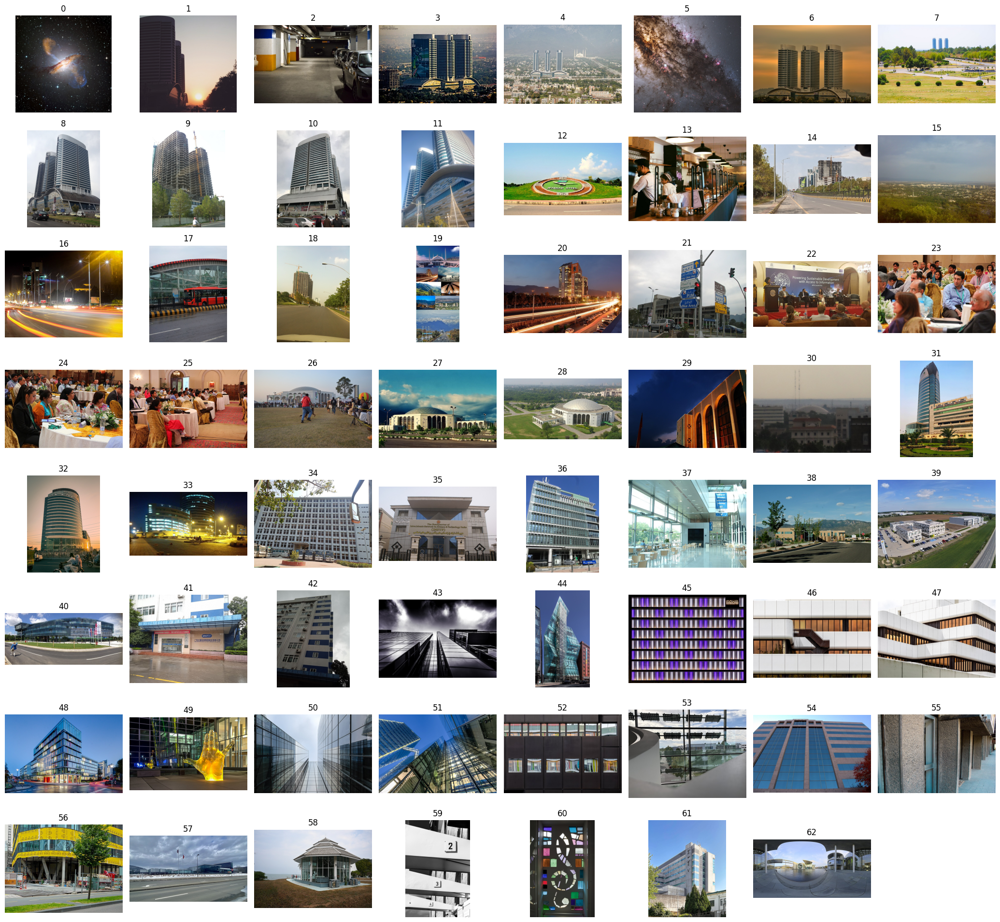

In [ ]:
import requests, os, io, time
from PIL import Image
import matplotlib.pyplot as plt

HEADERS = {"User-Agent": "building-match-test/0.1 (student project)"}
API = "https://commons.wikimedia.org/w/api.php"
FOLDER = "/content/data_raw/hard_neg"
os.makedirs(FOLDER, exist_ok=True)
for f in os.listdir(FOLDER): os.remove(f"{FOLDER}/{f}")

queries = ["NUST Islamabad campus building", "Islamabad modern building", "Centaurus Islamabad",
           "Blue Area Islamabad", "Serena Hotel Islamabad", "Jinnah Convention Centre",
           "Arfa Software Technology Park", "science and technology park building",
           "glass facade office building", "modern concrete glass building",
           "Pakistan university building", "COMSATS Islamabad"]

seen, saved = set(), []
for q in queries:
    params = {"action": "query", "format": "json", "generator": "search",
              "gsrsearch": f"{q} filetype:bitmap", "gsrnamespace": 6, "gsrlimit": 12,
              "prop": "imageinfo", "iiprop": "url|mime", "iiurlwidth": 800}
    got = 0
    try:
        r = requests.get(API, params=params, headers=HEADERS, timeout=30).json()
    except Exception as e:
        print(q, "-> request failed", e); continue
    for p in r.get("query", {}).get("pages", {}).values():
        info = p.get("imageinfo", [{}])[0]
        url = info.get("thumburl") or info.get("url")
        if not url or info.get("mime") != "image/jpeg" or url in seen:
            continue
        seen.add(url)
        try:
            img = Image.open(io.BytesIO(requests.get(url, headers=HEADERS, timeout=30).content)).convert("RGB")
            img.save(f"{FOLDER}/{len(saved):03d}.jpg", quality=90); saved.append(url); got += 1
        except Exception:
            continue
        time.sleep(0.3)
    print(f"{q!r}: {got} images")
print("total:", len(saved))

if saved:
    cols = 8; rows = (len(saved) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 2.4 * rows))
    for ax in (axes.flat if rows * cols > 1 else [axes]): ax.axis("off")
    for i, ax in zip(range(len(saved)), axes.flat):
        ax.imshow(Image.open(f"{FOLDER}/{i:03d}.jpg")); ax.set_title(str(i), fontsize=12)
    plt.tight_layout(); plt.show()

In [ ]:
import torch, glob, random, time, os, cv2, numpy as np
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd
from sklearn.metrics import roc_auc_score
random.seed(1); t0 = time.time()

DROP = [0,2,5,13,22,23,24,25,26,31,46,53,54,60,61,75,79,82]                       # <- numbers from the grid that are NOT valid hard negatives
OUT = "/content/nstp_det"
dev = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", dev)

extractor = SuperPoint(max_num_keypoints=1024).eval().to(dev)
matcher = LightGlue(features="superpoint").eval().to(dev)

def load(p, max_side=600):
    im = cv2.imread(p); s = max_side / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s) if s < 1 else im

def crop_nstp(img, label_file, margin=0.03):
    rows = [list(map(float, l.split()[1:5])) for l in open(label_file).read().splitlines() if l.strip()]
    x0 = min(r[0] - r[2] / 2 for r in rows); x1 = max(r[0] + r[2] / 2 for r in rows)
    y0 = min(r[1] - r[3] / 2 for r in rows); y1 = max(r[1] + r[3] / 2 for r in rows)
    H, W = img.shape[:2]
    return img[max(0, int((y0 - margin) * H)):min(H, int((y1 + margin) * H)),
               max(0, int((x0 - margin) * W)):min(W, int((x1 + margin) * W))]

def feats(im):
    t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(dev)
    with torch.no_grad():
        return extractor.extract(t)

def inliers(f0, f1):
    with torch.no_grad():
        out = matcher({"image0": f0, "image1": f1})
    f0, f1, out = [rbd(x) for x in (f0, f1, out)]
    m = out["matches"]
    if len(m) < 8: return 0
    p0 = f0["keypoints"][m[:, 0]].cpu().numpy().reshape(-1, 1, 2)
    p1 = f1["keypoints"][m[:, 1]].cpu().numpy().reshape(-1, 1, 2)
    H, mask = cv2.findHomography(p0, p1, cv2.USAC_MAGSAC, 8.0)
    return int(mask.sum()) if mask is not None else 0

pos_imgs = sorted(glob.glob(f"{OUT}/images/val/pos_*.jpg")) + sorted(glob.glob(f"{OUT}/images/train/pos_*_0.jpg"))
hard_all = sorted(glob.glob("/content/data_raw/hard_neg/*.jpg"))
hard = [p for i, p in enumerate(hard_all) if i not in DROP]
easy = sorted(glob.glob(f"{OUT}/images/val/neg_*.jpg"))[:20]
lbl = lambda p: p.replace("/images/", "/labels/").replace(".jpg", ".txt")
print("NSTP:", len(pos_imgs), "| hard negatives:", len(hard), "| easy negatives:", len(easy))

imgs = {p: load(p) for p in pos_imgs + hard + easy}
cand = random.sample(pos_imgs, 6)
crops = {p: crop_nstp(imgs[p], lbl(p)) for p in cand}
tf = {p: feats(imgs[p]) for p in imgs}

S = {}
for i, r in enumerate(cand):
    rf = feats(crops[r])
    for p in imgs:
        if p != r: S[(r, p)] = inliers(rf, tf[p])
    print(f"reference {i + 1}/6 done ({time.time() - t0:.0f}s)", flush=True)

def best(refs, p): return max(S[(r, p)] for r in refs)

print("\n--- HARD NEGATIVES ---")
for k in (2, 3):
    aucs, found = [], []
    for _ in range(40):
        refs = random.sample(cand, k)
        pos = [p for p in pos_imgs if p not in refs]
        sp, sn = [best(refs, p) for p in pos], [best(refs, p) for p in hard]
        aucs.append(roc_auc_score([1] * len(sp) + [0] * len(sn), sp + sn))
        found.append(np.mean([s > max(sn) for s in sp]))
    print(f"RESULT hard-neg | {k} refs: AUC {np.mean(aucs):.2f} (worst {np.min(aucs):.2f}) | "
          f"NSTP found with zero false alarms: {np.mean(found):.0%}")

top = sorted(hard, key=lambda p: -best(cand, p))[:5]
print("hard negatives that score highest (look at these):",
      [(os.path.basename(p), best(cand, p)) for p in top])

# --- crude distance test: shrink NSTP photos and paste them into other scenes ---
print("\n--- DISTANCE TEST (crude) ---")
R = cand[:3]
hard_max = max(best(R, p) for p in hard)
print("highest score among hard negatives with these 3 refs:", hard_max)
bgs = [load(p, 800) for p in (hard + easy)]
test_pos = [p for p in pos_imgs if p not in cand][:10]
for frac in (0.6, 0.4, 0.25):
    scores = []
    for p in test_pos:
        bg = cv2.resize(random.choice(bgs), (800, 600)); img = imgs[p]
        s = frac * 800 / img.shape[1]
        small = cv2.resize(img, None, fx=s, fy=s)
        h, w = small.shape[:2]
        h, w = min(h, 600), min(w, 800); small = small[:h, :w]
        y, x = random.randint(0, 600 - h), random.randint(0, 800 - w)
        comp = bg.copy(); comp[y:y + h, x:x + w] = small
        f = feats(comp)
        scores.append(max(inliers(feats(crops[r]), f) for r in R))
    print(f"building width = {int(frac * 100)}% of frame: median inliers {int(np.median(scores))}, "
          f"above the hard-negative max: {np.mean([s > hard_max for s in scores]):.0%}", flush=True)

device: cuda
NSTP: 32 | hard negatives: 48 | easy negatives: 20
reference 1/6 done (10s)
reference 2/6 done (13s)
reference 3/6 done (14s)
reference 4/6 done (16s)
reference 5/6 done (19s)
reference 6/6 done (21s)

--- HARD NEGATIVES ---
RESULT hard-neg | 2 refs: AUC 0.99 (worst 0.95) | NSTP found with zero false alarms: 91%
RESULT hard-neg | 3 refs: AUC 1.00 (worst 0.98) | NSTP found with zero false alarms: 97%
hard negatives that score highest (look at these): [('057.jpg', 45), ('014.jpg', 44), ('020.jpg', 38), ('003.jpg', 33), ('006.jpg', 29)]

--- DISTANCE TEST (crude) ---
highest score among hard negatives with these 3 refs: 45
building width = 60% of frame: median inliers 125, above the hard-negative max: 100%
building width = 40% of frame: median inliers 113, above the hard-negative max: 70%
building width = 25% of frame: median inliers 11, above the hard-negative max: 40%


In [ ]:
extractor = SuperPoint(max_num_keypoints=2048).eval().to(dev)   # replaces the 1024 one
HR = 1000
R = cand[:3]
top_hard = sorted(hard, key=lambda p: -best(cand, p))[:15]          # the hardest ones from before
sub_hard = list(dict.fromkeys(top_hard + random.sample(hard, 10)))

hi = {p: load(p, HR) for p in set(sub_hard + test_pos + R)}
ref_f = [feats(crop_nstp(hi[r], lbl(r))) for r in R]

hard_scores = [max(inliers(rf, feats(hi[p])) for rf in ref_f) for p in sub_hard]
hard_max2 = max(hard_scores)
print("hard negatives (hi-res, 2048 kp): max inliers", hard_max2, "| median", int(np.median(hard_scores)))

bgs_hr = [load(p, 1200) for p in sub_hard[:10]]
for frac in (0.4, 0.25, 0.15):
    scores = []
    for p in test_pos:
        bg = cv2.resize(random.choice(bgs_hr), (1200, 900)); img = hi[p]
        s = frac * 1200 / img.shape[1]
        small = cv2.resize(img, None, fx=s, fy=s)
        h, w = min(small.shape[0], 900), min(small.shape[1], 1200); small = small[:h, :w]
        y, x = random.randint(0, 900 - h), random.randint(0, 1200 - w)
        comp = bg.copy(); comp[y:y + h, x:x + w] = small
        f = feats(comp)
        scores.append(max(inliers(rf, f) for rf in ref_f))
    print(f"building width = {int(frac * 100)}%: median inliers {int(np.median(scores))}, "
          f"above the hard-negative max: {np.mean([s > hard_max2 for s in scores]):.0%}", flush=True)

hard negatives (hi-res, 2048 kp): max inliers 54 | median 7
building width = 40%: median inliers 124, above the hard-negative max: 80%
building width = 25%: median inliers 67, above the hard-negative max: 60%
building width = 15%: median inliers 8, above the hard-negative max: 10%


### Cell 1: upload 'ref', 'pos', 'neg' folders (in this order)

Before re-running the upload cell, clear the folders

In [ ]:
import shutil, os
for n in ("ref", "pos", "neg"):
    shutil.rmtree(f"/content/real/{n}", ignore_errors=True); os.makedirs(f"/content/real/{n}")

Upload

In [ ]:
import os
from google.colab import files
for name in ("ref", "pos", "neg"):
    os.makedirs(f"/content/real/{name}", exist_ok=True)
    print(f"Select the {name.upper()} photos:")
    os.chdir(f"/content/real/{name}"); files.upload()
os.chdir("/content")

Select the REF photos:


Saving IMG_0591.JPG to IMG_0591.JPG
Saving IMG_0592.JPG to IMG_0592.JPG
Saving IMG_0599.JPG to IMG_0599.JPG
Select the POS photos:


Saving f_0000.jpg to f_0000.jpg
Saving f_0003.jpg to f_0003.jpg
Saving f_0008.jpg to f_0008.jpg
Saving f_0019.jpg to f_0019.jpg
Saving f_0021.jpg to f_0021.jpg
Saving f_0022.jpg to f_0022.jpg
Saving f_0025.jpg to f_0025.jpg
Saving f_0026.jpg to f_0026.jpg
Select the NEG photos:


Saving f_0000.jpg to f_0000.jpg
Saving f_0001.jpg to f_0001.jpg
Saving f_0002.jpg to f_0002.jpg
Saving f_0003.jpg to f_0003.jpg
Saving f_0004.jpg to f_0004.jpg
Saving f_0005.jpg to f_0005.jpg
Saving f_0006.jpg to f_0006.jpg
Saving f_0007.jpg to f_0007.jpg
Saving f_0008.jpg to f_0008.jpg
Saving f_0009.jpg to f_0009.jpg
Saving f_0010.jpg to f_0010.jpg
Saving f_0011.jpg to f_0011.jpg
Saving f_0012.jpg to f_0012.jpg
Saving f_0014.jpg to f_0014.jpg
Saving f_0015.jpg to f_0015.jpg
Saving f_0016.jpg to f_0016.jpg
Saving f_0017.jpg to f_0017.jpg
Saving f_0019.jpg to f_0019.jpg
Saving f_0020.jpg to f_0020.jpg
Saving f_0024.jpg to f_0024.jpg
Saving f_0025.jpg to f_0025.jpg
Saving f_0027.jpg to f_0027.jpg
Saving f_0028.jpg to f_0028.jpg
Saving f_0029.jpg to f_0029.jpg
Saving f_0036.jpg to f_0036.jpg
Saving f_0037.jpg to f_0037.jpg
Saving f_0038.jpg to f_0038.jpg
Saving f_0039.jpg to f_0039.jpg
Saving f_0040.jpg to f_0040.jpg
Saving f_0041.jpg to f_0041.jpg
Saving f_0042.jpg to f_0042.jpg
Saving f

### Remove near duplicate images

In [ ]:
import glob, os, shutil
import numpy as np
from PIL import Image

def dhash(p, size=12):
    a = np.asarray(Image.open(p).convert("L").resize((size + 1, size)), dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()

THR = 18          # higher = removes more; 10-25 is a sensible range for 144-bit hashes

def thin(name, thr=THR):
    fs = sorted(p for p in glob.glob(f"/content/real/{name}/*") if p.lower().endswith((".jpg", ".jpeg", ".png")))
    os.makedirs(f"/content/real/{name}_near", exist_ok=True)
    kept, hs = [], []
    for f in fs:
        h = dhash(f)
        if all((h != k).sum() > thr for k in hs):
            kept.append(f); hs.append(h)
        else:
            shutil.move(f, f"/content/real/{name}_near/")
    print(f"{name}: {len(fs)} -> {len(kept)} kept")

thin("pos"); thin("neg")

pos: 8 -> 7 kept
neg: 60 -> 60 kept


### Cell 2: test

refs: 3 | same-building: 7 | other: 60
same building, inliers: [195, 356, 390, 468, 495, 541, 632]
other, inliers:         [5, 5, 5, 5, 6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 7, 7, 7, 7, 8, 8, 9, 9, 9, 10, 11, 11, 11, 12, 13, 13, 15, 18, 19, 19, 19, 20, 21, 22, 23, 24, 24, 25, 25, 25, 26, 26, 27, 29, 30, 31, 31, 31, 31, 32, 34, 34, 43, 45, 45, 48]
AUC: 1.0
cutoff just above the best wrong score (48): finds 100% of same-building photos


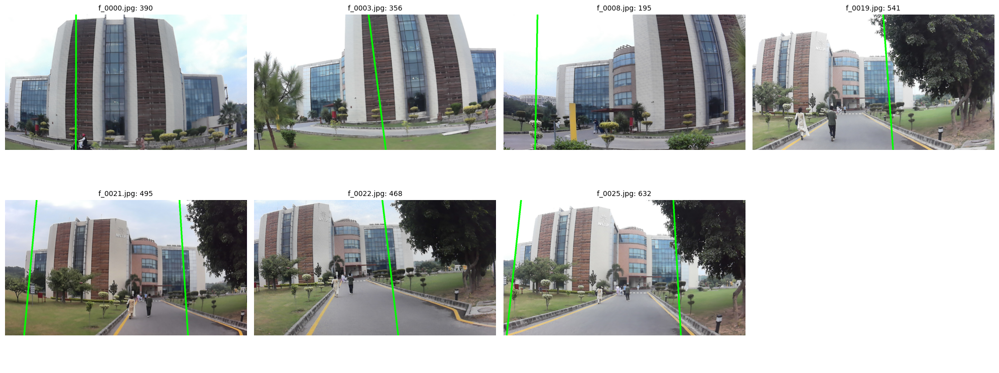

In [ ]:
import glob, os, cv2, torch, numpy as np
import matplotlib.pyplot as plt
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd
from sklearn.metrics import roc_auc_score

dev = "cuda" if torch.cuda.is_available() else "cpu"
extractor = SuperPoint(max_num_keypoints=2048).eval().to(dev)
matcher = LightGlue(features="superpoint").eval().to(dev)
R = "/content/real"
ls = lambda d: sorted(p for p in glob.glob(f"{R}/{d}/*") if p.lower().endswith((".jpg", ".jpeg", ".png")))

def load(p, max_side=1000):
    im = cv2.imread(p); s = max_side / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s) if s < 1 else im

def feats(im):
    t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(dev)
    with torch.no_grad(): return extractor.extract(t)

def match(f0, f1):
    with torch.no_grad(): out = matcher({"image0": f0, "image1": f1})
    f0, f1, out = [rbd(x) for x in (f0, f1, out)]
    m = out["matches"]
    if len(m) < 8: return 0, None
    p0 = f0["keypoints"][m[:, 0]].cpu().numpy().reshape(-1, 1, 2)
    p1 = f1["keypoints"][m[:, 1]].cpu().numpy().reshape(-1, 1, 2)
    H, mask = cv2.findHomography(p0, p1, cv2.USAC_MAGSAC, 8.0)
    return (int(mask.sum()), H) if mask is not None else (0, None)

refs, pos, neg = ls("ref"), ls("pos"), ls("neg")
print("refs:", len(refs), "| same-building:", len(pos), "| other:", len(neg))
ref_im = [load(p) for p in refs]; ref_f = [feats(i) for i in ref_im]

res = {}
for p in pos + neg:
    im = load(p); f = feats(im); best = (0, None, -1)
    for k, rf in enumerate(ref_f):
        n, H = match(rf, f)
        if n > best[0]: best = (n, H, k)
    res[p] = (best[0], best[1], best[2], im)

sp = [res[p][0] for p in pos]; sn = [res[p][0] for p in neg]
print("same building, inliers:", sorted(sp))
print("other, inliers:        ", sorted(sn))
if sp and sn:
    print("AUC:", round(roc_auc_score([1] * len(sp) + [0] * len(sn), sp + sn), 2))
    thr = max(sn) + 1
    print(f"cutoff just above the best wrong score ({max(sn)}): finds {np.mean([s >= thr for s in sp]):.0%} of same-building photos")

thr = (max(sn) + 1) if sn else 60
show = pos[:12]
cols = 4; rows = (len(show) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
for ax in np.atleast_1d(axes).flat: ax.axis("off")
for ax, p in zip(np.atleast_1d(axes).flat, show):
    n, H, k, im = res[p]; im = im.copy()
    if H is not None and n >= thr:
        h, w = ref_im[k].shape[:2]
        c = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
        cv2.polylines(im, [np.int32(cv2.perspectiveTransform(c, H))], True, (0, 255, 0), 6)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.set_title(f"{os.path.basename(p)}: {n}", fontsize=10)
plt.tight_layout(); plt.show()

frames where the projected outline is a sensible quadrilateral: 86% of 7


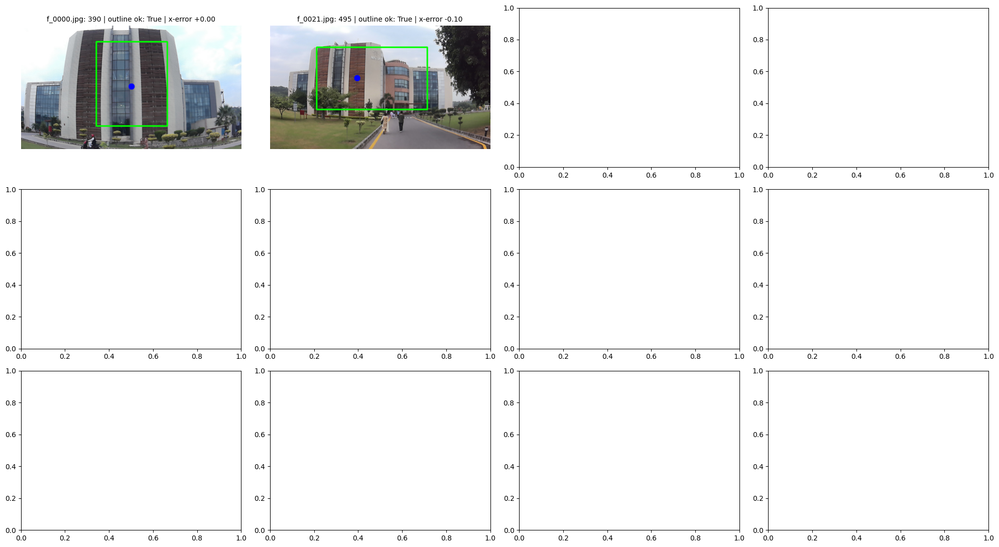

In [ ]:
import cv2, numpy as np, matplotlib.pyplot as plt, os

def match_pts(f0, f1):
    with torch.no_grad(): out = matcher({"image0": f0, "image1": f1})
    f0, f1, out = [rbd(x) for x in (f0, f1, out)]
    m = out["matches"]
    if len(m) < 8: return 0, None, None
    p0 = f0["keypoints"][m[:, 0]].cpu().numpy().reshape(-1, 1, 2)
    p1 = f1["keypoints"][m[:, 1]].cpu().numpy().reshape(-1, 1, 2)
    H, mask = cv2.findHomography(p0, p1, cv2.USAC_MAGSAC, 8.0)
    if mask is None: return 0, None, None
    keep = mask.ravel().astype(bool)
    return int(keep.sum()), H, p1[keep].reshape(-1, 2)

def quad_ok(H, rw, rh, W, Hh):
    c = np.float32([[0, 0], [rw, 0], [rw, rh], [0, rh]]).reshape(-1, 1, 2)
    q = cv2.perspectiveTransform(c, H).reshape(-1, 1, 2).astype(np.float32)
    area = cv2.contourArea(q)
    return bool(cv2.isContourConvex(q)) and 0.02 * W * Hh < area < 4 * W * Hh

rows = []
for p in pos:
    im = load(p); f = feats(im); best = (0, None, None, 0)
    for k, rf in enumerate(ref_f):
        n, H, pts = match_pts(rf, f)
        if n > best[0]: best = (n, H, pts, k)
    n, H, pts, k = best
    h, w = im.shape[:2]; rh, rw = ref_im[k].shape[:2]
    ok = H is not None and quad_ok(H, rw, rh, w, h)
    rows.append((p, im, n, pts, ok))

print("frames where the projected outline is a sensible quadrilateral:",
      f"{np.mean([r[4] for r in rows]):.0%} of {len(rows)}")

show = rows[::4][:12]
fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, (p, im, n, pts, ok) in zip(axes.flat, show):
    im = im.copy(); h, w = im.shape[:2]
    if pts is not None and len(pts) >= 8:
        x0, x1 = np.percentile(pts[:, 0], [5, 95]); y0, y1 = np.percentile(pts[:, 1], [5, 95])
        cv2.rectangle(im, (int(x0), int(y0)), (int(x1), int(y1)), (0, 255, 0), 5)
        cx, cy = np.median(pts, axis=0)
        cv2.circle(im, (int(cx), int(cy)), 14, (255, 0, 0), -1)
        err = (cx - w / 2) / w
    else:
        err = float("nan")
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off")
    ax.set_title(f"{os.path.basename(p)}: {n} | outline ok: {ok} | x-error {err:+.2f}", fontsize=10)
plt.tight_layout(); plt.show()

In [ ]:
import numpy as np
spreads, used = [], 0
for p, im, n, pts, ok in rows:
    f = feats(im); h, w = im.shape[:2]; cs = []
    for rf in ref_f:
        m, H, pt = match_pts(rf, f)
        if m >= 40 and pt is not None and len(pt) >= 8:
            cs.append(np.median(pt[:, 0]) / w)
    if len(cs) >= 2:
        spreads.append(max(cs) - min(cs)); used += 1
spreads = np.array(spreads)
print(f"frames matched by at least 2 references: {used} of {len(rows)}")
print("spread of the target x-position between references (fraction of frame width):")
print(f"  median {np.median(spreads):.2f} | 90th percentile {np.percentile(spreads, 90):.2f} | max {spreads.max():.2f}")

frames matched by at least 2 references: 7 of 7
spread of the target x-position between references (fraction of frame width):
  median 0.37 | 90th percentile 0.46 | max 0.49


In [ ]:
!pip install -q ultralytics==8.4.104
from ultralytics import YOLO
import glob, os

import os, numpy as np
det = None
try:
    from ultralytics import YOLO
    wp = "/content/runs/nstp_det2/weights/best.pt"
    det = YOLO(wp) if os.path.exists(wp) else None
except Exception as e:
    print("ultralytics not available:", e)
print("detector weights found:", det is not None)

out, det_hits = [], 0
for p, im, n, pts, ok in rows:
    f = feats(im); h, w = im.shape[:2]; allpts = []
    for rf in ref_f:
        m, H, pt = match_pts(rf, f)
        if m >= 40 and pt is not None:
            allpts.append(pt)
    if not allpts:
        continue
    U = np.vstack(allpts)
    cx_u = np.median(U[:, 0]) / w
    x0, x1 = np.percentile(U[:, 0], [5, 95]) / w
    d_cx = d_w = None
    if det is not None:
        r = det.predict(im, imgsz=(224, 320), conf=0.25, verbose=False)[0]
        if len(r.boxes):
            b = r.boxes[int(r.boxes.conf.argmax())].xyxy[0].cpu().numpy()
            d_cx, d_w = ((b[0] + b[2]) / 2) / w, (b[2] - b[0]) / w
            det_hits += 1
    out.append((cx_u, x1 - x0, d_cx, d_w))

print("frames used:", len(out), "of", len(rows))
print(f"matched points from ALL references: box width median {np.median([o[1] for o in out]):.2f} of the frame")
if det is not None:
    print("detector found a box in", det_hits, "frames")
    pairs = [(o[0], o[2]) for o in out if o[2] is not None]
    err = np.array([abs(a - b) for a, b in pairs])
    print(f"|matcher center - detector center|: median {np.median(err):.2f}, "
          f"90th percentile {np.percentile(err, 90):.2f}, max {err.max():.2f}  (fraction of frame width)")
    print(f"detector box width median: {np.median([o[3] for o in out if o[3] is not None]):.2f} of the frame")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.3/45.3 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 77.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
detector weights found: False
frames used: 7 of 7
matched points from ALL references: box width median 0.52 of the frame


frames matched by all 3 references: 5 of 7
pooled center, spread between different pairs of references (fraction of frame width): median 0.13 | 90th percentile 0.31 | max 0.34
pooled box width: median 0.52 of the frame


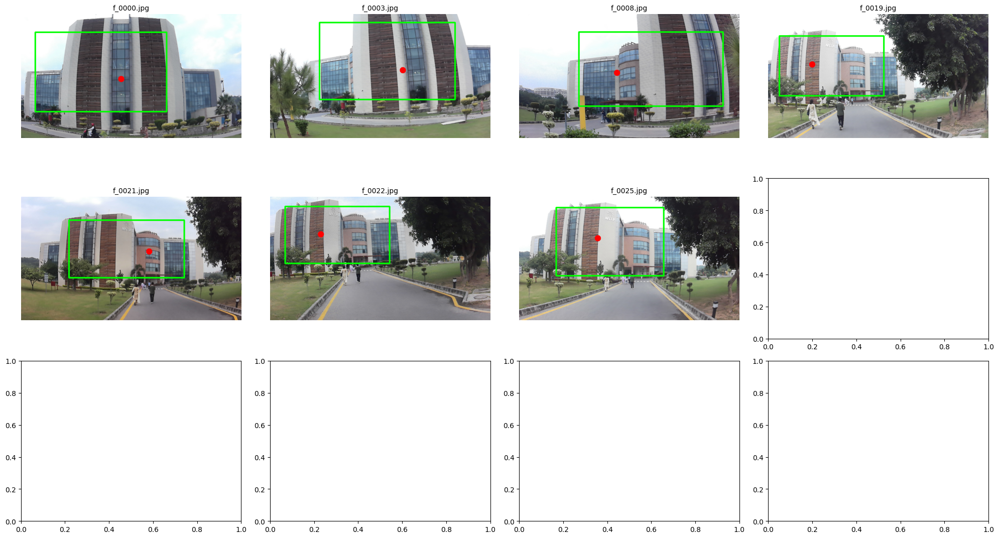

In [ ]:
import itertools, numpy as np, cv2, os
import matplotlib.pyplot as plt

def per_ref_points(im):
    f = feats(im); res = []
    for rf in ref_f:
        m, H, pt = match_pts(rf, f)
        res.append(pt if (m >= 40 and pt is not None and len(pt) >= 8) else None)
    return res

spreads_pair, widths, viz = [], [], []
for p, im, n, pts, ok in rows:
    h, w = im.shape[:2]
    pr = per_ref_points(im)
    good = [i for i, x in enumerate(pr) if x is not None]
    if len(good) >= 3:
        cs = [np.median(np.vstack([pr[a], pr[b]])[:, 0]) / w for a, b in itertools.combinations(good, 2)]
        spreads_pair.append(max(cs) - min(cs))
    if good:
        U = np.vstack([pr[i] for i in good])
        x0, x1 = np.percentile(U[:, 0], [5, 95]); y0, y1 = np.percentile(U[:, 1], [5, 95])
        widths.append((x1 - x0) / w)
        viz.append((p, im, U, (x0, y0, x1, y1)))

sp = np.array(spreads_pair)
print(f"frames matched by all 3 references: {len(sp)} of {len(rows)}")
print(f"pooled center, spread between different pairs of references (fraction of frame width): "
      f"median {np.median(sp):.2f} | 90th percentile {np.percentile(sp, 90):.2f} | max {sp.max():.2f}")
print(f"pooled box width: median {np.median(widths):.2f} of the frame")

fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for ax, (p, im, U, b) in zip(axes.flat, viz[::max(1, len(viz) // 12)][:12]):
    im = im.copy()
    cv2.rectangle(im, tuple(map(int, b[:2])), tuple(map(int, b[2:])), (0, 255, 0), 5)
    cx, cy = np.median(U, axis=0); cv2.circle(im, (int(cx), int(cy)), 14, (0, 0, 255), -1)
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); ax.axis("off"); ax.set_title(os.path.basename(p), fontsize=10)
plt.tight_layout(); plt.show()

### Lock-on script to run on a laptop now and on the Jetson later.
It takes a camera or a video file, matches each frame against all your reference photos, pools the matched points, and outputs a smoothed horizontal and vertical error.


In [ ]:
import cv2, torch, numpy as np, glob, time
from lightglue import LightGlue, SuperPoint
from lightglue.utils import rbd

SOURCE = 0            # 0 = USB camera, or a path like "walk.mp4"
REF_DIR = "/content/real/ref"
MAX_SIDE = 800        # larger helps at distance but is slower; tune after measuring speed
KEYPOINTS = 1024      # tests used 1024 and 2048
MIN_INLIERS = 80      # best single-reference match must reach this to count as "found"
POOL_MIN = 40         # references with at least this many matches contribute points
LOCK_AFTER = 3        # consecutive "found" frames before locking
LOSE_AFTER = 5        # consecutive "not found" frames before unlocking
ALPHA = 0.3           # smoothing: higher reacts faster, lower is steadier
DEADBAND = 0.05       # errors smaller than this (fraction of frame size) are reported as 0

dev = "cuda" if torch.cuda.is_available() else "cpu"
extractor = SuperPoint(max_num_keypoints=KEYPOINTS).eval().to(dev)
matcher = LightGlue(features="superpoint").eval().to(dev)

def resize(im):
    s = MAX_SIDE / max(im.shape[:2])
    return cv2.resize(im, None, fx=s, fy=s) if s < 1 else im

def feats(im):
    t = torch.from_numpy(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)).permute(2, 0, 1).float().div(255).to(dev)
    with torch.no_grad():
        return extractor.extract(t)

def match(f0, f1):
    with torch.no_grad():
        out = matcher({"image0": f0, "image1": f1})
    f0, f1, out = [rbd(x) for x in (f0, f1, out)]
    m = out["matches"]
    if len(m) < 8:
        return 0, None
    p0 = f0["keypoints"][m[:, 0]].cpu().numpy().reshape(-1, 1, 2)
    p1 = f1["keypoints"][m[:, 1]].cpu().numpy().reshape(-1, 1, 2)
    H, mask = cv2.findHomography(p0, p1, cv2.USAC_MAGSAC, 8.0)
    if mask is None:
        return 0, None
    keep = mask.ravel().astype(bool)
    return int(keep.sum()), p1[keep].reshape(-1, 2)

# Match both lowercase and uppercase extensions
refs = sorted(
    glob.glob(f"{REF_DIR}/*.jpg") + glob.glob(f"{REF_DIR}/*.png") + glob.glob(f"{REF_DIR}/*.jpeg") +
    glob.glob(f"{REF_DIR}/*.JPG") + glob.glob(f"{REF_DIR}/*.PNG") + glob.glob(f"{REF_DIR}/*.JPEG")
)
assert refs, "put 2-3 reference photos in the ref folder"
ref_f = [feats(resize(cv2.imread(p))) for p in refs]
print("references:", len(refs), "| device:", dev)

cap = cv2.VideoCapture(SOURCE)
locked, hits, misses, smooth = False, 0, 0, None
t_last, fps = time.time(), 0.0

while True:
    ok, frame = cap.read()
    if not ok:
        break
    im = resize(frame); h, w = im.shape[:2]
    f = feats(im)

    scores, pts_all = [], []
    for rf in ref_f:
        n, pts = match(rf, f)
        scores.append(n)
        if n >= POOL_MIN and pts is not None:
            pts_all.append(pts)
    best = max(scores)
    found = best >= MIN_INLIERS and len(pts_all) > 0

    if found:
        hits, misses = hits + 1, 0
        c = np.median(np.vstack(pts_all), axis=0)
        smooth = c if smooth is None else (1 - ALPHA) * smooth + ALPHA * c
    else:
        misses, hits = misses + 1, 0

    if not locked and hits >= LOCK_AFTER:
        locked = True
    if locked and misses >= LOSE_AFTER:
        locked, smooth = False, None

    ex = ey = None
    if locked and smooth is not None:
        ex, ey = (smooth[0] - w / 2) / w, (smooth[1] - h / 2) / h
        ex = 0.0 if abs(ex) < DEADBAND else ex
        ey = 0.0 if abs(ey) < DEADBAND else ey
        cv2.circle(im, (int(smooth[0]), int(smooth[1])), 12, (0, 255, 0), -1)
    cv2.circle(im, (w // 2, h // 2), 8, (0, 0, 255), 2)

    now = time.time(); fps = 0.9 * fps + 0.1 / max(now - t_last, 1e-6); t_last = now
    status = f"LOCKED ex={ex:+.2f} ey={ey:+.2f}" if locked else f"searching (best={best})"
    cv2.putText(im, f"{status} | {fps:.1f} FPS", (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (255, 255, 255), 2)
    cv2.imshow("lock-on test", im)
    if locked:
        print(f"ex={ex:+.3f} ey={ey:+.3f} best={best}")        # positive ex = building is to the right of center
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break
cap.release(); cv2.destroyAllWindows()

references: 3 | device: cuda


In [ ]:
import itertools, random
from sklearn.metrics import roc_auc_score
random.seed(0)

allp = pos + neg
fc = {p: feats(load(p)) for p in allp}
M = {(i, p): match(ref_f[i], fc[p])[0] for i in range(len(refs)) for p in allp}

for k in (1, 2, 3):
    combos = list(itertools.combinations(range(len(refs)), k))
    combos = random.sample(combos, min(30, len(combos)))
    aucs, found, gaps = [], [], []
    for c in combos:
        sp = [max(M[(i, p)] for i in c) for p in pos]
        sn = [max(M[(i, p)] for i in c) for p in neg]
        aucs.append(roc_auc_score([1] * len(sp) + [0] * len(sn), sp + sn))
        found.append(np.mean([s > max(sn) for s in sp]))
        gaps.append((min(sp), max(sn)))
    print(f"{k} reference photo(s): AUC {np.mean(aucs):.3f} (worst {np.min(aucs):.3f}) | "
          f"found with zero false alarms {np.mean(found):.0%} (worst {np.min(found):.0%}) | "
          f"typical lowest NSTP {int(np.median([g[0] for g in gaps]))} vs highest wrong {int(np.median([g[1] for g in gaps]))}")


KeyboardInterrupt: 

Remove duplicate files